In [ ]:
#program 7 RNN
import numpy as np
from tensorflow.keras.datasets import reuters
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN,Dense
from tensorflow.keras.preprocessing.sequence import pad_sequences
vocab_size=5000
(x_train, _), _=reuters.load_data(num_words=vocab_size)
input_sequences=[]
max_seq_len= 20  
for seq in x_train[:1000]:
    seq=seq[:max_seq_len]
    for i in range(1, len(seq)):
        input_sequences.append(seq[:i+1])
max_len =max(len(seq)for seq in input_sequences)
input_sequences=pad_sequences(input_sequences, maxlen=max_len, padding="pre")
X=input_sequences[:, :-1]
y=input_sequences[:, -1]
model=Sequential()
model.add(Embedding(vocab_size,32,input_length=max_len-1))
model.add(SimpleRNN(50))
model.add(Dense(vocab_size,activation='softmax'))
model.compile(loss='sparse_categorical_crossentropy',optimizer='adam',metrics=['accuracy'])
model.fit(X,y,epochs=10,batch_size=128)
def predict_next_word(seed_seq):
    seed_seq=pad_sequences([seed_seq],maxlen=max_len-1,padding='pre')
    predicted=np.argmax(model.predict(seed_seq),axis=-1)
    return predicted[0]
word_index=reuters.get_word_index()
reverse_word_index={v:k for k,v in word_index.items()}
def decode_word(index):
    return reverse_word_index.get(index-3,'?')
seed=x_train[35][:90]
predicted_index=predict_next_word(seed)
print("Seed Sequences:",seed)
print("Predicted word index:",predicted_index)
print("Predicted word:",decode_word(predicted_index))

In [ ]:
import numpy as np
from tensorflow.keras.datasets import imdb
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.preprocessing.sequence import pad_sequences

vocab_size = 5000
(x_train, _), _ = imdb.load_data(num_words=vocab_size)

input_sequences = []
max_seq_len = 20
 
for seq in x_train[:1000]:
    seq = seq[:max_seq_len]
    for i in range(1, len(seq)):
        input_sequences.append(seq[:i+1])

max_len = max(len(seq) for seq in input_sequences)
input_sequences = pad_sequences(input_sequences, maxlen=max_len, padding='pre')

x = input_sequences[:, :-1]
y = input_sequences[:, -1]

model = Sequential()
model.add(Embedding(vocab_size, 32, input_length=max_len-1))
model.add(SimpleRNN(50))
model.add(Dense(vocab_size, activation='softmax'))

model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(x, y, epochs=10, batch_size=128)

def predict_next_word(seed_seq):
    seed_seq = pad_sequences([seed_seq], maxlen=max_len-1, padding='pre')
    predicted = np.argmax(model.predict(seed_seq), axis=-1)
    return predicted[0]

word_index = imdb.get_word_index()
reverse_word_index = {v: k for k, v in word_index.items()}

def decode_word(index):
    return reverse_word_index.get(index - 3, "?")

sample_seed = x_train[1001][:5]
predicted_index = predict_next_word(sample_seed)
print("Seed text:", " ".join(decode_word(idx) for idx in sample_seed))
print("Predicted next word:", decode_word(predicted_index))

In [ ]:
#PROGRAM 8
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from tensorflow.keras.layers import LSTM
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint

filename = 'alice-in-wonderland.txt'
raw_text = open(filename, 'r', encoding='utf-8').read()
raw_text = raw_text.lower()

chars = sorted(list(set(raw_text)))
char_to_int = dict((c, i) for i, c in enumerate(chars))

n_chars = len(raw_text)
n_vocab = len(chars)
print("Total Characters: ", n_chars)
print("Total Vocab: ", n_vocab)

seq_length = 100

dataX = []
dataY = []
for i in range(0, n_chars - seq_length, 1):
    seq_in = raw_text[i:i + seq_length]
    seq_out = raw_text[i + seq_length]
    dataX.append([char_to_int[char] for char in seq_in])
    dataY.append(char_to_int[seq_out])
    
n_patterns = len(dataX)
print("Total Patterns: ", n_patterns)
X = np.reshape(dataX, (n_patterns, seq_length, 1))
X = X / float(n_vocab)
y = to_categorical(dataY)
model = Sequential()
model.add(LSTM(256, input_shape=(X.shape[1], X.shape[2])))
model.add(Dropout(0.2))
model.add(Dense(y.shape[1], activation='softmax'))
model.compile(loss='categorical_crossentropy', optimizer='adam')

filepath = "weights-improvement-{epoch:02d}-{loss:.4f}.keras"
checkpoint = ModelCheckpoint(filepath, monitor='accuracy', verbose=1, save_best_only=True, mode='min')
callbacks_list = [checkpoint]

model.fit(X, y, epochs=2, batch_size=128, callbacks=callbacks_list)

filename="weights-improvement-18-2.0199.keras"
model.load_weights(filename)
model.compile(loss='categorical_crossentropy',optimizer='adam')

int_to_char = dict((i, c) for i, c in enumerate(chars))
import sys
start = np.random.randint(0, len(dataX) - 1)
pattern = dataX[start]
print("Seed:")
print("\"", ''.join([int_to_char[value] for value in pattern]), "\"")

print("\nGenerated Text:")
for i in range(1000):
    x = np.reshape(pattern, (1, len(pattern), 1))
    x = x / float(n_vocab)
    prediction = model.predict(x, verbose=0)
    index = np.argmax(prediction)
    result = int_to_char[index]
    seq_in =[int_to_char[value] for value in pattern]
    sys.stdout.write(result)
    pattern.append(index)
    pattern = pattern[1:len(pattern)]
print("\nDone.")

In [ ]:
#PROGRAM 9
import numpy as np
from tensorflow.keras import layers,models
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import text_to_word_sequence
max_features=10000
maxlen=500
(x_train,y_train),(x_test,y_test)=imdb.load_data(num_words=max_features)
x_train=pad_sequences(x_train,maxlen=maxlen)
x_test=pad_sequences(x_test,maxlen=maxlen)
model=models.Sequential([
    layers.Embedding(max_features,128,mask_zero=True),
    layers.LSTM(64),
    layers.Dense(1,activation='sigmoid')
])  
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)
model.fit(
    x_train,y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)
loss,accuracy=model.evaluate(x_test,y_test)
print(f"Test Accuracy:{accuracy*100:.2f}%")

word_index=imdb.get_word_index()
word_index={k:v+3 for k,v in word_index.items()}

def encode(text):
    words=text_to_word_sequence(text)
    encoded=[1] 
    for word in words:
        index=word_index.get(word,2)
        if index>=max_features:
            index=2
        encoded.append(index)
    return encoded
new_text="the movie was not good"
encoded=encode(new_text)
padded=pad_sequences([encoded],maxlen=maxlen)
prediction=model.predict(padded)
print("positive" if prediction [0][0] >=0.5 else "negative")

In [ ]:
#program 8
import sys
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import ModelCheckpoint

# 1. Load and preprocess text
filename = 'alice-in-wonderland.txt'
raw_text = open(filename, 'r', encoding='utf-8').read()
raw_text = raw_text.lower()

# Create mapping of unique characters to integers
chars = sorted(list(set(raw_text)))
char_to_int = dict((c, i) for i, c in enumerate(chars))
int_to_char = dict((i, c) for i, c in enumerate(chars))

n_chars = len(raw_text)
n_vocab = len(chars)
print("Total Characters: ", n_chars)
print("Total Vocab: ", n_vocab)

# 2. Prepare training sequences
seq_length = 100
dataX = []
dataY = []
for i in range(0, n_chars - seq_length, 1):
    seq_in = raw_text[i:i + seq_length]
    seq_out = raw_text[i + seq_length]
    dataX.append([char_to_int[char] for char in seq_in])
    dataY.append(char_to_int[seq_out])

n_patterns = len(dataX)
print("Total Patterns: ", n_patterns)

X = np.reshape(dataX, (n_patterns, seq_length, 1))
X = X / float(n_vocab)
y = to_categorical(dataY)

model = Sequential()
model.add(LSTM(256, input_shape=(X.shape[1], X.shape[2])))
model.add(Dropout(0.2))
model.add(Dense(y.shape[1], activation='softmax'))
model.compile(loss='categorical_crossentropy', optimizer='adam')

filepath = "weights-improvement-{epoch:02d}-{loss:.4f}.keras"
checkpoint = ModelCheckpoint(filepath, monitor='loss', verbose=1, save_best_only=True, mode='min')
callbacks_list = [checkpoint]

model.fit(X, y, epochs=2, batch_size=128, callbacks=callbacks_list)

filename = "weights-improvement-02-2.8006.keras"
model.load_weights(filename)
model.compile(loss='categorical_crossentropy', optimizer='adam')

start = np.random.randint(0, len(dataX) - 1)
pattern = dataX[start]
print("Seed:")
print("\"", ''.join([int_to_char[value] for value in pattern]), "\"")

print("\nGenerated Text:")
for i in range(1000):
    x = np.reshape(pattern, (1, len(pattern), 1))
    x = x / float(n_vocab)
    prediction = model.predict(x, verbose=0)
    index = np.argmax(prediction)
    result = int_to_char[index]
    sys.stdout.write(result)
    pattern.append(index)
    pattern = pattern[1:len(pattern)]
print("\nDone.")


Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6936 - val_loss: 0.6935
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6934 - val_loss: 0.6933
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6932 - val_loss: 0.6932
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6931 - val_loss: 0.6930
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6929 - val_loss: 0.6928
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6927 - val_loss: 0.6927
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6926 - val_loss: 0.6925
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6924 - val_loss: 0.6923
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6922 - val_loss: 0.6921
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.6921 - val_loss: 0.6920
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 342us/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 362us/step


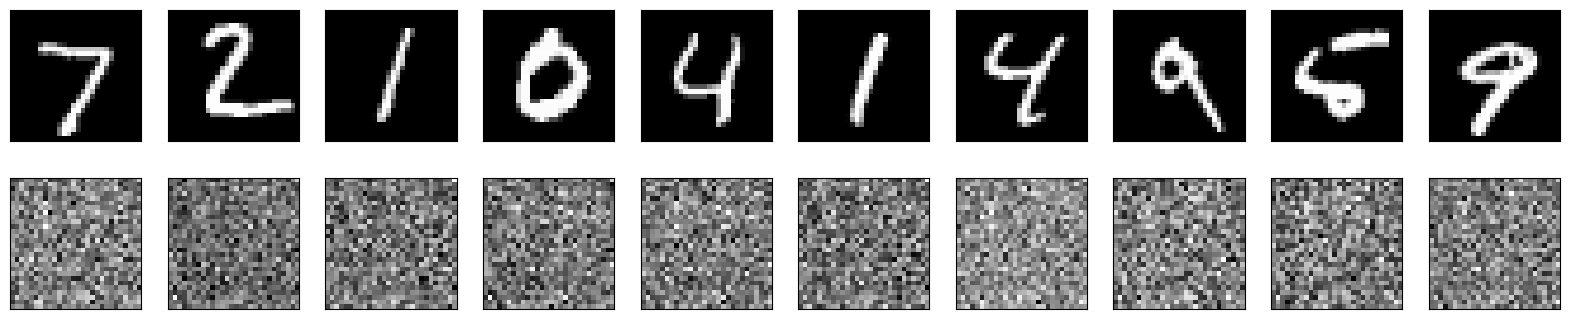

In [7]:
#program12
from keras.layers import Input, Dense
from keras.models import Model
from keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt

input_img = Input(shape=(784,))
encoded = Dense(32, activation='relu')(input_img)
decoded = Dense(784, activation='sigmoid')(encoded)

autoencoder = Model(input_img, decoded)
encoder = Model(input_img, encoded)

encoded_input = Input(shape=(32,))
decoder_layer = autoencoder.layers[-1]
decoder = Model(encoded_input, decoder_layer(encoded_input))

autoencoder.compile(optimizer='adadelta', loss='binary_crossentropy')

(x_train, _), (x_test, _) = mnist.load_data()
x_train = x_train.astype('float32') / 255.
x_test = x_test.astype('float32') / 255.
x_train = x_train.reshape((len(x_train), np.prod(x_train.shape[1:])))
x_test = x_test.reshape((len(x_test), np.prod(x_test.shape[1:])))

autoencoder.fit(x_train, x_train,
                epochs=10,
                batch_size=256,
                validation_data=(x_test, x_test),
                verbose=1)

encoded_imgs = encoder.predict(x_test)
decoded_imgs = decoder.predict(encoded_imgs)

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_imgs[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

In [ ]:
#program-11
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np
dataset, info = tfds.load('oxford_iiit_pet:4.0.0', with_info=True)
def resize(input_image, input_mask):
    input_image = tf.image.resize(input_image, (128, 128), method="nearest")
    input_mask = tf.image.resize(input_mask, (128, 128), method="nearest")
    return input_image, input_mask
def augment(input_image, input_mask):
    if tf.random.uniform(()) > 0.5:
 # Random flipping of the image and mask
    input_image = tf.image.flip_left_right(input_image)
    input_mask = tf.image.flip_left_right(input_mask)
    return input_image, input_mask
def normalize(input_image, input_mask):
    input_image = tf.cast(input_image, tf.float32) / 255.0
    input_mask -= 1
    return input_image, input_mask
def load_image_train(datapoint):
    input_image = datapoint["image"]
    input_mask = datapoint["segmentation_mask"]
    input_image, input_mask = resize(input_image, input_mask)
    input_image, input_mask = augment(input_image, input_mask)
    input_image, input_mask = normalize(input_image, input_mask)
    return input_image, input_mask
def load_image_test(datapoint):
    input_image = datapoint["image"]
    input_mask = datapoint["segmentation_mask"]
    input_image, input_mask = resize(input_image, input_mask)
    input_image, input_mask = normalize(input_image, input_mask)
    return input_image, input_mask
train_dataset = dataset["train"].map(load_image_train, 
num_parallel_calls=tf.data.AUTOTUNE)
test_dataset = dataset["test"].map(load_image_test, 
num_parallel_calls=tf.data.AUTOTUNE)
BATCH_SIZE = 64
BUFFER_SIZE = 1000
train_batches = 
train_dataset.cache().shuffle(BUFFER_SIZE).batch(BATCH_SIZE).repeat()
train_batches = train_batches.prefetch(buffer_size=tf.data.experimental.AUTOTUNE)
validation_batches = test_dataset.take(3000).batch(BATCH_SIZE)
test_batches = test_dataset.skip(3000).take(669).batch(BATCH_SIZE)
def display(display_list):
    plt.figure(figsize=(15, 15))
    title = ["Input Image", "True Mask", "Predicted Mask"]
    for i in range(len(display_list)):
        plt.subplot(1, len(display_list), i+1)
        plt.title(title[i])
        plt.imshow(tf.keras.utils.array_to_img(display_list[i]))
        plt.axis("off")
    plt.show()
sample_batch = next(iter(train_batches))
random_index = np.random.choice(sample_batch[0].shape[0])
sample_image, sample_mask = sample_batch[0][random_index], 
sample_batch[1][random_index]
display([sample_image, sample_mask])
def double_conv_block(x, n_filters):
 # Conv2D then ReLU activation
    x = layers.Conv2D(n_filters, 3, padding = "same", activation = "relu", kernel_initializer = "he_normal")(x)
 # Conv2D then ReLU activation
    x = layers.Conv2D(n_filters, 3, padding = "same", activation = "relu", kernel_initializer = "he_normal")(x)
    return x
def downsample_block(x, n_filters):
    f = double_conv_block(x, n_filters)
 p = layers.MaxPool2D(2)(f)
39
 p = layers.Dropout(0.3)(p)
 return f, p
def upsample_block(x, conv_features, n_filters):
 # upsample
 x = layers.Conv2DTranspose(n_filters, 3, 2, padding="same")(x)
 # concatenate
 x = layers.concatenate([x, conv_features])
 # dropout
 x = layers.Dropout(0.3)(x)
 # Conv2D twice with ReLU activation
 x = double_conv_block(x, n_filters)
 return x
def build_unet_model():
inputs = layers.Input(shape=(128,128,3))
f1, p1 = downsample_block(inputs, 64)
f2, p2 = downsample_block(p1, 128)
f3, p3 = downsample_block(p2, 256)
f4, p4 = downsample_block(p3, 512)
bottleneck = double_conv_block(p4, 1024)
u6 = upsample_block(bottleneck, f4, 512)
u7 = upsample_block(u6, f3, 256)
u8 = upsample_block(u7, f2, 128)
u9 = upsample_block(u8, f1, 64)
outputs = layers.Conv2D(3, 1, padding="same", activation = "softmax")(u9)
unet_model = tf.keras.Model(inputs, outputs, name="U-Net")
return unet_model 
unet_model = build_unet_model()
unet_model.compile(optimizer=tf.keras.optimizers.Adam(),
 loss="sparse_categorical_crossentropy",
 metrics=["accuracy"])
NUM_EPOCHS = 7
TRAIN_LENGTH = info.splits["train"].num_examples
STEPS_PER_EPOCH = TRAIN_LENGTH // BATCH_SIZE
#3680/64=57
VAL_SUBSPLITS = 5
TEST_LENTH = info.splits["test"].num_examples
VALIDATION_STEPS = TEST_LENTH // BATCH_SIZE // VAL_SUBSPLITS
40
model_history = unet_model.fit(train_batches,
 epochs=NUM_EPOCHS,
 steps_per_epoch=STEPS_PER_EPOCH,
 validation_steps=VALIDATION_STEPS,
 validation_data=test_batches)
def create_mask(pred_mask):
pred_mask = tf.argmax(pred_mask, axis=-1)
pred_mask = pred_mask[..., tf.newaxis]
return pred_mask[0]
def show_predictions(dataset=None, num=1):
if dataset:
 for image, mask in dataset.take(num):
 pred_mask = unet_model.predict(image)
 display([image[0], mask[0], create_mask(pred_mask)])
else:
 display([sample_image, sample_mask,
 create_mask(unet_model.predict(sample_image[tf.newaxis, ...]))])
count = 0
for i in test_batches:
 count +=1
print("number of batches:", count)
show_predictions()

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow_datasets as tfds

# Load dataset
dataset, info = tfds.load("oxford_iiit_pet", with_info=True)


# Preprocessing functions
def resize(input_image, input_mask):
  input_image = tf.image.resize(input_image, (128, 128), method="nearest")
  input_mask = tf.image.resize(input_mask, (128, 128), method="nearest")
  return input_image, input_mask


def augment(input_image, input_mask):
  if tf.random.uniform(()) > 0.5:
    # Random flipping of the image and mask
    input_image = tf.image.flip_left_right(input_image)
    input_mask = tf.image.flip_left_right(input_mask)
  return input_image, input_mask


def normalize(input_image, input_mask):
  input_image = tf.cast(input_image, tf.float32) / 255.0
  input_mask -= 1
  return input_image, input_mask


def load_image_train(datapoint):
  input_image = datapoint["image"]
  input_mask = datapoint["segmentation_mask"]
  input_image, input_mask = resize(input_image, input_mask)
  input_image, input_mask = augment(input_image, input_mask)
  input_image, input_mask = normalize(input_image, input_mask)
  return input_image, input_mask


def load_image_test(datapoint):
  input_image = datapoint["image"]
  input_mask = datapoint["segmentation_mask"]
  input_image, input_mask = resize(input_image, input_mask)
  input_image, input_mask = normalize(input_image, input_mask)
  return input_image, input_mask


# Prepare datasets
train_dataset = dataset["train"].map(
    load_image_train, num_parallel_calls=tf.data.AUTOTUNE
)
test_dataset = dataset["test"].map(
    load_image_test, num_parallel_calls=tf.data.AUTOTUNE
)

BATCH_SIZE = 64
BUFFER_SIZE = 1000

train_batches = (
    train_dataset.cache().shuffle(BUFFER_SIZE).batch(BATCH_SIZE).repeat()
)
train_batches = train_batches.prefetch(buffer_size=tf.data.AUTOTUNE)

validation_batches = test_dataset.take(3000).batch(BATCH_SIZE)
test_batches = test_dataset.skip(3000).take(669).batch(BATCH_SIZE)


# Display helper function
def display(display_list):
  plt.figure(figsize=(15, 15))
  title = ["Input Image", "True Mask", "Predicted Mask"]
  for i in range(len(display_list)):
    plt.subplot(1, len(display_list), i + 1)
    plt.title(title[i])
    plt.imshow(tf.keras.utils.array_to_img(display_list[i]))
    plt.axis("off")
  plt.show()


# Display a sample image and mask
sample_batch = next(iter(train_batches))
random_index = np.random.choice(sample_batch[0].shape[0])
sample_image, sample_mask = (
    sample_batch[0][random_index],
    sample_batch[1][random_index],
)
display([sample_image, sample_mask])


# U-Net building blocks
def double_conv_block(x, n_filters):
  x = layers.Conv2D(
      n_filters, 3, padding="same", activation="relu", kernel_initializer="he_normal"
  )(x)
  x = layers.Conv2D(
      n_filters, 3, padding="same", activation="relu", kernel_initializer="he_normal"
  )(x)
  return x


def downsample_block(x, n_filters):
  f = double_conv_block(x, n_filters)
  p = layers.MaxPool2D(2)(f)
  p = layers.Dropout(0.3)(p)
  return f, p


def upsample_block(x, conv_features, n_filters):
  x = layers.Conv2DTranspose(n_filters, 3, 2, padding="same")(x)
  x = layers.concatenate([x, conv_features])
  x = layers.Dropout(0.3)(x)
  x = double_conv_block(x, n_filters)
  return x


def build_unet_model():
  inputs = layers.Input(shape=(128, 128, 3))

  # Encoder
  f1, p1 = downsample_block(inputs, 64)
  f2, p2 = downsample_block(p1, 128)
  f3, p3 = downsample_block(p2, 256)
  f4, p4 = downsample_block(p3, 512)

  # Bottleneck
  bottleneck = double_conv_block(p4, 1024)

  # Decoder
  u6 = upsample_block(bottleneck, f4, 512)
  u7 = upsample_block(u6, f3, 256)
  u8 = upsample_block(u7, f2, 128)
  u9 = upsample_block(u8, f1, 64)

  outputs = layers.Conv2D(3, 1, padding="same", activation="softmax")(u9)
  unet_model = tf.keras.Model(inputs, outputs, name="U-Net")
  return unet_model


# Compile model
unet_model = build_unet_model()
unet_model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

# Training parameters
NUM_EPOCHS = 7
TRAIN_LENGTH = info.splits["train"].num_examples
STEPS_PER_EPOCH = TRAIN_LENGTH // BATCH_SIZE  # 3680 // 64 = 57
VAL_SUBSPLITS = 5
TEST_LENGTH = info.splits["test"].num_examples
VALIDATION_STEPS = TEST_LENGTH // BATCH_SIZE // VAL_SUBSPLITS

# Train model
model_history = unet_model.fit(
    train_batches,
    epochs=NUM_EPOCHS,
    steps_per_epoch=STEPS_PER_EPOCH,
    validation_steps=VALIDATION_STEPS,
    validation_data=validation_batches,
)


# Prediction helpers
def create_mask(pred_mask):
  pred_mask = tf.argmax(pred_mask, axis=-1)
  pred_mask = pred_mask[..., tf.newaxis]
  return pred_mask[0]


def show_predictions(dataset=None, num=1):
  if dataset:
    for image, mask in dataset.take(num):
      pred_mask = unet_model.predict(image)
      display([image[0], mask[0], create_mask(pred_mask)])
  else:
    pred_mask = unet_model.predict(sample_image[tf.newaxis, ...])
    display([sample_image, sample_mask, create_mask(pred_mask)])


# Count test batches and display prediction
count = 0
for i in test_batches:
  count += 1
print("number of batches:", count)

show_predictions()
